# Tool retrieval with a permission filter (MCP-Zero + AgentBound)

AI Assignment 1

**What we do here:** MCP-Zero finds the right tool for a request using embeddings. AgentBound gives the list of permissions a tool can ask for (filesystem.read, network.client and so on). We join the two ideas: first retrieve the tools, then throw away any tool that needs a permission we have not allowed. Then we check what changes with and without this filter.

**What this is not:** it is a small demo. The tools are made up, and there is no Docker sandbox like in AgentBound. We only check permissions in Python.

Run the cells from top to bottom.

## 1. Install the libraries

In [1]:
!pip install -q sentence-transformers pandas matplotlib

## 2. Load the embedding model
We use `all-MiniLM-L6-v2` from sentence-transformers. The MCP-Zero paper used OpenAI's text-embedding-3-large, but we wanted something free that does not need an API key.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")
print("Model loaded.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded.


## 3. Our tool list
18 made-up tools. Each has a name, a server, a description and the permissions it needs. The permission names come from AgentBound's table. (In the paper permissions are given per server, here we gave them per tool to keep it simple.)

In [3]:
tools = [
 {"name":"read_file","server":"file system","description":"Read the contents of a file from disk given its path","capabilities":["filesystem.read"]},
 {"name":"write_file","server":"file system","description":"Create a new file or overwrite an existing file with the given text","capabilities":["filesystem.write"]},
 {"name":"list_directory","server":"file system","description":"List the files and subfolders inside a directory","capabilities":["filesystem.read"]},
 {"name":"delete_file","server":"file system","description":"Permanently delete a file or folder from disk","capabilities":["filesystem.delete"]},
 {"name":"fetch_url","server":"web access","description":"Download and return the content of a web page from a URL","capabilities":["network.client"]},
 {"name":"web_search","server":"search engine","description":"Search the internet and return a list of relevant results for a query","capabilities":["network.client"]},
 {"name":"query_database","server":"database","description":"Run a read-only SQL query on a database and return the rows","capabilities":["network.client"]},
 {"name":"download_and_save","server":"web and file system","description":"Download a file from a URL and save it to the local disk","capabilities":["network.client","filesystem.write"]},
 {"name":"run_shell","server":"terminal","description":"Execute a shell command on the operating system and return its output","capabilities":["system.exec"]},
 {"name":"run_python_script","server":"code runner","description":"Run a Python script file and return its printed output","capabilities":["filesystem.read","system.exec"]},
 {"name":"read_env_var","server":"system settings","description":"Read the value of an environment variable such as an API key or PATH","capabilities":["system.env.read"]},
 {"name":"kill_process","server":"process manager","description":"List running processes or terminate a process by its ID","capabilities":["system.process"]},
 {"name":"capture_screen","server":"desktop","description":"Take a screenshot of the current screen","capabilities":["peripheral.screen.capture"]},
 {"name":"record_audio","server":"audio","description":"Record sound from the microphone","capabilities":["peripheral.microphone"]},
 {"name":"get_location","server":"device location","description":"Get the current geographic location of the device","capabilities":["location"]},
 {"name":"read_clipboard","server":"clipboard","description":"Read the text currently stored in the clipboard","capabilities":["clipboard.read"]},
 {"name":"send_notification","server":"notifications","description":"Show a desktop notification with a message","capabilities":["notifications.post"]},
 {"name":"start_server","server":"network server","description":"Start a local server that accepts incoming network connections","capabilities":["network.server"]},
]
by_name = {t["name"]: t for t in tools}
assert len(tools) == 18 and len(by_name) == 18, "tool names must be unique"
print("Tools loaded:", len(tools))

Tools loaded: 18


## 4. Turn the tools into vectors
Every tool becomes one text of the form `Server: ... Tool: ...`, the same two fields MCP-Zero uses for its requests. The shape printed below should be (18, 384).

In [4]:
# Each tool is embedded in MCP-Zero's two-field style: server + tool description
tool_texts = [f"Server: {t['server']}. Tool: {t['description']}" for t in tools]
tool_emb = model.encode(tool_texts, normalize_embeddings=True)
print("Embedding matrix shape:", tool_emb.shape)   # expect (18, 384)

Embedding matrix shape: (18, 384)


## 5. Retrieval and the permission filter
- `retrieve()` returns the top-k tools by cosine similarity
- `is_allowed()` is true only if every permission of the tool is inside the allowed set
- `apply_policy()` removes the tools that are not allowed

In [5]:
def retrieve(request, k=3):
    """MCP-Zero-style retrieval: cosine similarity (vectors are normalised, so dot product)."""
    q = model.encode([request], normalize_embeddings=True)[0]
    sims = tool_emb @ q
    order = np.argsort(-sims)[:k]
    return [(tools[i], float(sims[i])) for i in order]

def is_allowed(tool, allowed):
    """A tool is allowed only if ALL its required capabilities are in the allowed set."""
    return set(tool["capabilities"]).issubset(allowed)

def apply_policy(results, allowed):
    """Our extension: drop retrieved tools that need a capability outside the allowed set."""
    return [(t, s) for t, s in results if is_allowed(t, allowed)]

ALLOWED = {"filesystem.read", "filesystem.write", "network.client"}
print("Policy (allowed capabilities):", sorted(ALLOWED))

Policy (allowed capabilities): ['filesystem.read', 'filesystem.write', 'network.client']


## 6. Try it on one request

In [6]:
req = "Server: file system. Tool: open a text file and show me what is inside"
before = retrieve(req, k=3)
after = apply_policy(before, ALLOWED)
print("REQUEST:", req)
print("\nBefore filter:")
for t, s in before:
    print(f"  {t['name']:<18} score={s:.3f}  caps={t['capabilities']}  allowed={is_allowed(t, ALLOWED)}")
print("\nAfter filter:")
for t, s in after:
    print(f"  {t['name']:<18} score={s:.3f}")

REQUEST: Server: file system. Tool: open a text file and show me what is inside

Before filter:
  read_file          score=0.669  caps=['filesystem.read']  allowed=True
  write_file         score=0.635  caps=['filesystem.write']  allowed=True
  list_directory     score=0.559  caps=['filesystem.read']  allowed=True

After filter:
  read_file          score=0.669
  write_file         score=0.635
  list_directory     score=0.559


## 7. Test requests
15 requests, each with the tool we expect to get back. For 7 of them the tool is allowed by our policy, for the other 8 it is not.

In [7]:
# (request, expected tool). 7 expected tools are allowed by the policy, 8 are not.
tests = [
 ("Server: file system. Tool: open a text file and show me what is inside", "read_file"),
 ("Server: file system. Tool: save this text into a new file", "write_file"),
 ("Server: file system. Tool: show what files are in a folder", "list_directory"),
 ("Server: internet. Tool: get the text of a web page from its address", "fetch_url"),
 ("Server: search engine. Tool: look up information about a topic online", "web_search"),
 ("Server: database. Tool: run a SELECT query and return the rows", "query_database"),
 ("Server: web and file system. Tool: download a file from a link and store it on my computer", "download_and_save"),
 ("Server: file system. Tool: erase a file so it no longer exists", "delete_file"),
 ("Server: terminal. Tool: run a command line instruction", "run_shell"),
 ("Server: code runner. Tool: execute a python program and show its output", "run_python_script"),
 ("Server: system settings. Tool: get the value of an environment variable", "read_env_var"),
 ("Server: operating system. Tool: stop a running program by its process id", "kill_process"),
 ("Server: desktop. Tool: take a picture of what is on the screen", "capture_screen"),
 ("Server: audio. Tool: capture sound from the microphone", "record_audio"),
 ("Server: device. Tool: find out where the device is located right now", "get_location"),
]
assert all(exp in by_name for _, exp in tests)
print("Test requests:", len(tests))


Test requests: 15


## 8. With the filter vs without it
What the `outcome` column means:
- `served`: the tool was allowed and it was found
- `retrieval miss`: the tool was allowed but did not come in the top-k
- `blocked by policy`: the tool was not allowed, it was retrieved and then removed
- `not retrieved`: the tool was not allowed and never came in the top-k

In [8]:
def evaluate(allowed, k=3):
    rows = []
    for req, exp in tests:
        before = retrieve(req, k)
        after = apply_policy(before, allowed)
        b_names = [t["name"] for t, _ in before]
        a_names = [t["name"] for t, _ in after]
        exp_allowed = is_allowed(by_name[exp], allowed)
        if exp_allowed:
            outcome = "served" if exp in a_names else "retrieval miss"
        else:
            outcome = "blocked by policy" if exp in b_names else "not retrieved"
        rows.append({
            "request": req.split("Tool: ")[1],
            "expected": exp,
            "expected_allowed": exp_allowed,
            "top1": b_names[0],
            "top1_correct": b_names[0] == exp,
            "hit_in_topk": exp in b_names,
            "violating_before": sum(not is_allowed(t, allowed) for t, _ in before),
            "violating_after": sum(not is_allowed(t, allowed) for t, _ in after),
            "outcome": outcome,
        })
    df = pd.DataFrame(rows)
    ok = df[df.expected_allowed]
    summary = {
        "requests": len(df),
        "top1_accuracy": round(df.top1_correct.mean(), 3),
        "topk_hit_rate": round(df.hit_in_topk.mean(), 3),
        "allowed_requests": len(ok),
        "allowed_served_after_filter": int((ok.outcome == "served").sum()),
        "violating_tools_before": int(df.violating_before.sum()),
        "violating_tools_after": int(df.violating_after.sum()),
        "blocked_requests": int((~df.expected_allowed).sum()),
        "blocked_by_policy": int((df.outcome == "blocked by policy").sum()),
        "blocked_not_retrieved_anyway": int((df.outcome == "not retrieved").sum()),
    }
    return df, summary

K = 3
df, summary = evaluate(ALLOWED, K)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 70)
display(df)
print("\nSUMMARY (k =", K, ")")
for key, v in summary.items():
    print(f"  {key}: {v}")

,request,expected,expected_allowed,top1,top1_correct,hit_in_topk,violating_before,violating_after,outcome
0,open a text file and show me what is inside,read_file,True,read_file,True,True,0,0,served
1,save this text into a new file,write_file,True,write_file,True,True,0,0,served
2,show what files are in a folder,list_directory,True,list_directory,True,True,1,0,served
3,get the text of a web page from its address,fetch_url,True,fetch_url,True,True,1,0,served
4,look up information about a topic online,web_search,True,web_search,True,True,1,0,served
5,run a SELECT query and return the rows,query_database,True,query_database,True,True,1,0,served
6,download a file from a link and store it on my computer,download_and_save,True,download_and_save,True,True,0,0,served
7,erase a file so it no longer exists,delete_file,False,delete_file,True,True,1,0,blocked by policy
8,run a command line instruction,run_shell,False,run_shell,True,True,3,0,blocked by policy
9,execute a python program and show its output,run_python_script,False,run_python_script,True,True,3,0,blocked by policy



SUMMARY (k = 3 )
  requests: 15
  top1_accuracy: 1.0
  topk_hit_rate: 1.0
  allowed_requests: 7
  allowed_served_after_filter: 7
  violating_tools_before: 25
  violating_tools_after: 0
  blocked_requests: 8
  blocked_by_policy: 8
  blocked_not_retrieved_anyway: 0


## 9. Chart: risky tools before and after the filter

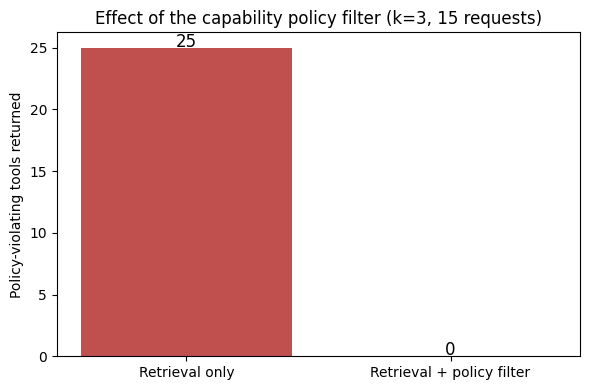

In [9]:
labels = ["Retrieval only", "Retrieval + policy filter"]
values = [summary["violating_tools_before"], summary["violating_tools_after"]]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(labels, values, color=["#c0504d", "#1fa89a"])
for i, v in enumerate(values):
    ax.text(i, v + 0.1, str(v), ha="center", fontsize=12)
ax.set_ylabel("Policy-violating tools returned")
ax.set_title(f"Effect of the capability policy filter (k={K}, {len(tests)} requests)")
plt.tight_layout()
plt.savefig("violations_chart.png", dpi=200)
plt.show()

## 10. Extra: trying different policies

In [10]:
policies = {
    "strict (read only)":      {"filesystem.read"},
    "moderate (read + net)":   {"filesystem.read", "network.client"},
    "main (read, write, net)": {"filesystem.read", "filesystem.write", "network.client"},
    "permissive (+ shell)":    {"filesystem.read", "filesystem.write", "network.client", "system.exec"},
}
rows = []
for name, pol in policies.items():
    _, s = evaluate(pol, K)
    rows.append({
        "policy": name,
        "violating_before": s["violating_tools_before"],
        "violating_after": s["violating_tools_after"],
        "allowed_requests": s["allowed_requests"],
        "allowed_served": s["allowed_served_after_filter"],
    })
policy_df = pd.DataFrame(rows)
display(policy_df)

,policy,violating_before,violating_after,allowed_requests,allowed_served
0,strict (read only),38,0,2,2
1,moderate (read + net),30,0,5,5
2,"main (read, write, net)",25,0,7,7
3,permissive (+ shell),15,0,9,9


## 11. Save the results

In [11]:
df.to_csv("results.csv", index=False)
policy_df.to_csv("policy_comparison.csv", index=False)
print("Saved results.csv, policy_comparison.csv and violations_chart.png (see the Files panel on the left).")

Saved results.csv, policy_comparison.csv and violations_chart.png (see the Files panel on the left).


## 12. Extra: what is left after the filter for the blocked requests
For the requests whose expected tool is not allowed, this prints what was retrieved and what is still there after filtering.

In [12]:
for _, row in df[~df.expected_allowed].iterrows():
    req_full = [r for r, e in tests if e == row.expected][0]
    before = retrieve(req_full, K)
    after = apply_policy(before, ALLOWED)
    print(f"{row.expected:<18} retrieved: {[t['name'] for t, _ in before]}  ->  kept: {[t['name'] for t, _ in after]}")

delete_file        retrieved: ['delete_file', 'write_file', 'read_file']  ->  kept: ['write_file', 'read_file']
run_shell          retrieved: ['run_shell', 'run_python_script', 'read_env_var']  ->  kept: []
run_python_script  retrieved: ['run_python_script', 'run_shell', 'read_env_var']  ->  kept: []
read_env_var       retrieved: ['read_env_var', 'run_shell', 'get_location']  ->  kept: []
kill_process       retrieved: ['kill_process', 'run_shell', 'delete_file']  ->  kept: []
capture_screen     retrieved: ['capture_screen', 'send_notification', 'run_shell']  ->  kept: []
record_audio       retrieved: ['record_audio', 'run_python_script', 'fetch_url']  ->  kept: ['fetch_url']
get_location       retrieved: ['get_location', 'read_env_var', 'run_shell']  ->  kept: []


## 13. Extra: normal user queries vs Server/Tool requests
Same 15 intents, but written the way a user would type them (no "Server:" and "Tool:" part). We check whether the right tool still comes up on top.

In [13]:
raw_tests = [
 ("Can you check what's in my notes.txt?", "read_file"),
 ("Save this paragraph as summary.txt", "write_file"),
 ("What files are in my Downloads?", "list_directory"),
 ("What does example.com say?", "fetch_url"),
 ("Find me some information about solar panels", "web_search"),
 ("How many customers signed up last month?", "query_database"),
 ("Grab this PDF from the link and keep it on my laptop", "download_and_save"),
 ("Get rid of old_report.docx", "delete_file"),
 ("Run ls -la for me", "run_shell"),
 ("Run my analysis.py file", "run_python_script"),
 ("What is my OPENAI_API_KEY set to?", "read_env_var"),
 ("Chrome is frozen, close it", "kill_process"),
 ("Show me what's on my screen", "capture_screen"),
 ("Record my voice for a minute", "record_audio"),
 ("Where am I right now?", "get_location"),
]

def accuracy(queries, k=3):
    top1 = hit = 0
    for q, exp in queries:
        names = [t["name"] for t, _ in retrieve(q, k)]
        top1 += names[0] == exp
        hit += exp in names
    return top1, hit

r1, rk = accuracy(raw_tests)
s1, sk = accuracy(tests)
print(f"Raw user queries      : top-1 {r1}/15, top-3 {rk}/15")
print(f"Server/Tool requests  : top-1 {s1}/15, top-3 {sk}/15")

Raw user queries      : top-1 10/15, top-3 13/15
Server/Tool requests  : top-1 15/15, top-3 15/15
